In [1]:
using JuMP
import DataFrames
import HiGHS
import Plots
import StatsPlots
import Ipopt

In [2]:
function ThermalGenerator(
    min::Float64,
    max::Float64,
    fixed_cost::Float64,
    variable_cost::Float64,
)
    return (
        min = min,
        max = max,
        fixed_cost = fixed_cost,
        variable_cost = variable_cost,
    )
end
generators = [
    ThermalGenerator(0.0, 1000.0, 1000.0, 50.0),
    ThermalGenerator(300.0, 1000.0, 0.0, 100.0),
]

2-element Vector{@NamedTuple{min::Float64, max::Float64, fixed_cost::Float64, variable_cost::Float64}}:
 (min = 0.0, max = 1000.0, fixed_cost = 1000.0, variable_cost = 50.0)
 (min = 300.0, max = 1000.0, fixed_cost = 0.0, variable_cost = 100.0)

In [ ]:
WindGenerator(variable_cost::Float64) = (variable_cost = variable_cost,)
wind_generator = WindGenerator(50.0)

(variable_cost = 0.0,)

In [4]:
function Scenario(demand::Float64, wind::Float64)
    return (demand = demand, wind = wind)
end
scenario = Scenario(1500.0, 200.0)

(demand = 1500.0, wind = 200.0)

In [5]:
function thermal_cost_function(g)
    if g <= 500
        return g
    else
        return g + 1e-2 * (g - 500)^2
    end
end
function solve_nonlinear_economic_dispatch(
    generators::Vector,
    wind,
    scenario;
    silent::Bool = false,
)
    model = Model(Ipopt.Optimizer)
    if silent
        set_silent(model)
    end
    @operator(model, op_tcf, 1, thermal_cost_function)
    N = length(generators)
    @variable(model, generators[i].min <= g[i=1:N] <= generators[i].max)
    @variable(model, 0 <= w <= scenario.wind)
    @objective(
        model,
        Min,
        sum(generators[i].variable_cost * op_tcf(g[i]) for i in 1:N) +
        wind.variable_cost * w,
    )
    @constraint(model, sum(g[i] for i in 1:N) + sqrt(w) == scenario.demand)
    optimize!(model)
    assert_is_solved_and_feasible(model)
    return (
        g = value.(g),
        w = value(w),
        wind_spill = scenario.wind - value(w),
        total_cost = objective_value(model),
    )
end

solution =
    solve_nonlinear_economic_dispatch(generators, wind_generator, scenario)


******************************************************************************
This program contains Ipopt, a library for large-scale nonlinear optimization.
 Ipopt is released as open source code under the Eclipse Public License (EPL).
         For more information visit https://github.com/coin-or/Ipopt
******************************************************************************

This is Ipopt version 3.14.19, running with linear solver MUMPS 5.9.0.

Number of nonzeros in equality constraint Jacobian...:        3
Number of nonzeros in inequality constraint Jacobian.:        0
Number of nonzeros in Lagrangian Hessian.............:        3

Total number of variables............................:        3
                     variables with only lower bounds:        0
                variables with lower and upper bounds:        3
                     variables with only upper bounds:        0
Total number of equality constraints.................:        1
Total number of inequality c

(g = [847.3509933774712, 648.6754966887423], w = 15.788781193899029, wind_spill = 184.21121880610096, total_cost = 190455.298013245)

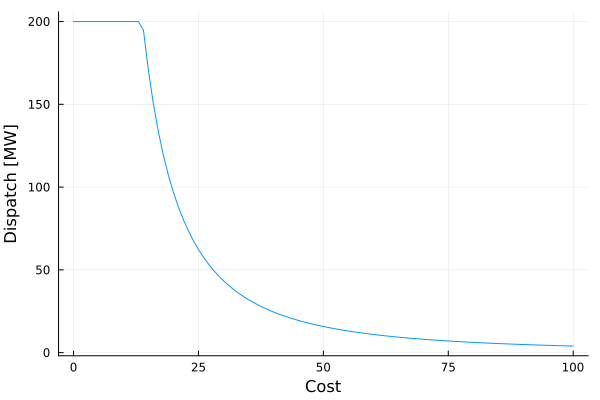

In [6]:
wind_cost = 0.0:1:100
wind_dispatch = Float64[]
for c in wind_cost
    sol = solve_nonlinear_economic_dispatch(
        generators,
        WindGenerator(c),
        scenario;
        silent = true,
    )
    push!(wind_dispatch, sol.w)
end
Plots.plot(
    wind_cost,
    wind_dispatch;
    xlabel = "Cost",
    ylabel = "Dispatch [MW]",
    label = false,
)

In [13]:
# ---------------------------------------------------------
# Wind generator definition
# ---------------------------------------------------------

WindGenerator() = (
    variable_cost = 0.0,
)

wind_generator = WindGenerator()
# ---------------------------------------------------------
# Thermal generator cost function
# ---------------------------------------------------------

function thermal_cost_function(g)

    if g <= 500
        return g
    else
        return g + 1e-2 * (g - 500)^2
    end

end


# ---------------------------------------------------------
# Economic dispatch
# ---------------------------------------------------------

function solve_nonlinear_economic_dispatch(
    generators::Vector,
    wind,
    scenario;
    silent::Bool = false,
)

    model = Model(Ipopt.Optimizer)

    if silent
        set_silent(model)
    end

    # Register nonlinear thermal cost function
    @operator(model, op_tcf, 1, thermal_cost_function)

    N = length(generators)

    # -----------------------------------------------------
    # Generator outputs
    # -----------------------------------------------------

    @variable(
        model,
        generators[i].min <= g[i=1:N] <= generators[i].max
    )

    # Wind output used
    @variable(model, w >= 0)

    @constraint(model, w == scenario.wind)

    # -----------------------------------------------------
    # Objective: minimize total generation cost
    # -----------------------------------------------------

    @objective(
        model,
        Min,
        sum(
            generators[i].fixed_cost +
            generators[i].variable_cost * op_tcf(g[i])
            for i in 1:N
        )
        +
        wind.variable_cost * w
    )

    # -----------------------------------------------------
    # Power balance
    # -----------------------------------------------------

    @constraint(
        model,
        sum(g[i] for i in 1:N) + w == scenario.demand
    )

    # -----------------------------------------------------
    # Solve
    # -----------------------------------------------------

    optimize!(model)

    assert_is_solved_and_feasible(model)

    # -----------------------------------------------------
    # Get dispatch results
    # -----------------------------------------------------

    g_value = value.(g)
    w_value = value(w)

    total_cost = objective_value(model)

    # ---------------------------------------------------------
    # Determine marginal generator and market-clearing price
    # ---------------------------------------------------------

    marginal_generator = nothing
    market_price = nothing

    for i in 1:N

        # Check whether generator i is marginal.
        # A marginal generator is operating strictly
        # between its minimum and maximum limits.
        if (
            g_value[i] > generators[i].min + 1e-5 &&
            g_value[i] < generators[i].max - 1e-5
        )

            marginal_generator = i

            # Derivative of thermal_cost_function
            if g_value[i] <= 500
                marginal_factor = 1.0
            else
                marginal_factor = 1.0 + 2e-2 * (g_value[i] - 500)
            end

            # Marginal cost of this thermal generator
            market_price =
                generators[i].variable_cost * marginal_factor

            break
        end
    end

    # -----------------------------------------------------
    # If no generator is strictly between limits,
    # identify the generator closest to the margin.
    # -----------------------------------------------------

    if marginal_generator === nothing

        for i in 1:N

            if g_value[i] > generators[i].min + 1e-5

                marginal_generator = i

                if g_value[i] <= 500
                    market_price = generators[i].variable_cost
                else
                    market_price =
                        generators[i].variable_cost *
                        (
                            1 +
                            2e-2 * (g_value[i] - 500)
                        )
                end

                break
            end
        end
    end

    # ---------------------------------------------------------
    # Wind market revenue
    # ---------------------------------------------------------

    wind_revenue = market_price * w_value

    wind_cost = wind.variable_cost * w_value

    wind_profit = wind_revenue - wind_cost

    # -----------------------------------------------------
    # Return results
    # -----------------------------------------------------

    return (
        g = g_value,
        w = w_value,

        market_price = market_price,

        wind_revenue = wind_revenue,
        wind_cost = wind_cost,
        wind_profit = wind_profit,

        total_cost = total_cost,

        marginal_generator = marginal_generator,
    )

end

solution =
    solve_nonlinear_economic_dispatch(generators, wind_generator, scenario)

This is Ipopt version 3.14.19, running with linear solver MUMPS 5.9.0.

Number of nonzeros in equality constraint Jacobian...:        4
Number of nonzeros in inequality constraint Jacobian.:        0
Number of nonzeros in Lagrangian Hessian.............:        2

Total number of variables............................:        3
                     variables with only lower bounds:        1
                variables with lower and upper bounds:        2
                     variables with only upper bounds:        0
Total number of equality constraints.................:        2
Total number of inequality constraints...............:        0
        inequality constraints with only lower bounds:        0
   inequality constraints with lower and upper bounds:        0
        inequality constraints with only upper bounds:        0

iter    objective    inf_pr   inf_du lg(mu)  ||d||  lg(rg) alpha_du alpha_pr  ls
   0  3.1300500e+04 1.20e+03 2.50e+01  -1.0 0.00e+00    -  0.00e+00 0.00e+00 

(g = [716.6666666666639, 583.3333333333361], w = 200.0, market_price = 266.6666666666639, wind_revenue = 53333.33333333278, wind_cost = 0.0, wind_profit = 53333.33333333278, total_cost = 125583.33333333331, marginal_generator = 1)

In [ ]:
function Scenario(demand::Float64, wind::Float64)
    return (demand = demand, wind = wind)
end
scenario = Scenario(600.0, 50.0)

WindGenerator() = (
    variable_cost = 0.0,
)

wind_generator = WindGenerator()

generators = [
    (
        min = 0.0,
        max = 250.0,
        fixed_cost = 150.0,
        variable_cost = 1.0,
    ),
    (
        min = 0.0,
        max = 300.0,
        fixed_cost = 600.0,
        variable_cost = 1.0,
    ),
    (
        min = 0.0,
        max = 270.0,
        fixed_cost = 600.0,
        variable_cost = 1.0,
    )
]

function thermal_cost_function_1(g)
    return 0.11*g^2 + 5*g + 150
end

function thermal_cost_function_2(g)
    return 0.085*g^2 + 1.2*g + 600
end

function thermal_cost_function_3(g)
    return 0.1225*g^2 + g + 600
end

thermal_cost_functions = [
    thermal_cost_function_1,
    thermal_cost_function_2,
    thermal_cost_function_3
]

function solve_nonlinear_economic_dispatch(
    generators::Vector,
    wind,
    scenario;
    silent::Bool = true,
)

    model = Model(Ipopt.Optimizer)

    if silent
        set_silent(model)
    end

    # Number of thermal generators
    N = 3

    @operator(model, op_tcf_1, 1, thermal_cost_function_1)
    @operator(model, op_tcf_2, 1, thermal_cost_function_2)
    @operator(model, op_tcf_3, 1, thermal_cost_function_3)

    @variable(
        model,
        generators[i].min <= g[i=1:N] <= generators[i].max
    )

    # All available wind power is sold
    @variable(model, w >= 0)
    @constraint(model, w == scenario.wind)

    @objective(
        model,
        Min,
        generators[1].variable_cost * op_tcf_1(g[1]) +
        generators[2].variable_cost * op_tcf_2(g[2]) +
        generators[3].variable_cost * op_tcf_3(g[3])
    )

    # Power balance
    @constraint(
        model,
        g[1] + g[2] + g[3] + w == scenario.demand
    )

    optimize!(model)
    assert_is_solved_and_feasible(model)

    g_value = value.(g)
    w_value = value(w)

    total_cost = objective_value(model)

    marginal_generator = nothing
    market_price = nothing

    # Check all three thermal generators
    for i in 1:N

        if (
            g_value[i] > generators[i].min + 1e-5 &&
            g_value[i] < generators[i].max - 1e-5
        )

            marginal_generator = i

            h = 1e-5

            marginal_factor =
                (
                    thermal_cost_functions[i](g_value[i] + h) -
                    thermal_cost_functions[i](g_value[i] - h)
                ) / (2h)

            market_price =
                generators[i].variable_cost *
                marginal_factor

            break
        end
    end

    wind_revenue = market_price * w_value

    # Wind has zero production cost
    wind_cost = 0.0

    return (
        g = g_value,
        w = w_value,
        market_price = market_price,
        wind_revenue = wind_revenue,
        wind_cost = wind_cost,
        total_cost = total_cost,
        marginal_generator = marginal_generator,
    )

end


solution =
    solve_nonlinear_economic_dispatch(
        generators,
        wind_generator,
        scenario
    )

(g = [160.1842798044542, 229.65024445274983, 160.165475742796], w = 50.0, market_price = 40.24054157980572, wind_revenue = 2012.027078990286, wind_cost = 0.0, total_cost = 13034.482512222641, marginal_generator = 1)